# 20 — The milestone-managed book: does a model beat a careful analyst's lookup two years in?

Notebook 14 showed that, two years after the request, the landmark model ranks the requests still in the queue far better than the entry model and the plain lookup (criterion C8). This notebook asks the question a portfolio manager would ask next, as a registered test: if I keep 25 or 50 of the utility-scale requests still in the queue at that point, does the model's choice realise more operations and MW than the choice of a lookup that knows the same dated agreement status — and can the model's level be repaired at the landmark with outcomes already known that day?

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02/04/06 |
| in | `data/interim/milestones.parquet` | notebook 13 — dated agreements |
| in | `data/processed/predictions_v2.parquet` | notebook 11 — the fair baseline's entry P(operation by 5 years) |
| in | `data/processed/predictions_landmark.parquet` | notebook 14 — to check the refit reproduces the landmark model |
| out | `results/success_criteria_v4.csv`, `results/success_criteria_v4_registered.json` | criteria C15–C17, written before any test number (decision #58) |
| out | `results/managed_book_pool.csv` | the pool at the +2 landmark |
| out | `results/managed_books.csv`, `results/managed_book_bootstrap.csv` | each chooser's books, point and resampled |
| out | `results/managed_book_composition.csv` | what each book holds (agreement known, region) |
| out | `results/landmark_level_repair.csv`, `results/landmark_level_calibration.csv` | the level repair at the landmark (C17) |
| out | `results/success_criteria_v4_scored.csv` | the ten registered lines, scored |
| out | `figures/F18_managed_book.*`, `figures/20_managed_book/*` | F18 and the notebook's figures |
| out | `results/managed_book_checks.csv` | this notebook's checks |
| out | `results/recommended_books.csv`, `results/recommended_books_curve.csv`, `figures/F24_book_per_region.*` | how many to add per region at the two-year milestone (section 10; an extension of C15, not registered) |

## Setup

In [1]:
import hashlib
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, evaluation, landmark, paths, plots, portfolio, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "20_managed_book"
START = time.time()


def save(fig, name, caption):
    """Save a figure of this notebook under figures/20_managed_book/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Registration (decision #58)

This cell is the registration. It was run and committed on its own before any later cell existed, so every rule below — the pool, the landmark, the book sizes, the cap, the choosers, the outcome, the resampling and the thesis rule — was fixed before a book was chosen or a number scored. On every later run the cell checks that the file on disk is the registered one and stops if anything differs.

Why these rules. The pool is notebook 14's +2 risk set restricted to 20 MW and more, the cohort of C6–C12. The landmark model's view is the one notebook 14 already published as best two years in ("agreement updated": the dated agreement flag, congestion frozen at entry because updating it is the known artefact). The decisive comparator is a lookup that **also knows whether the agreement has been executed**: beating the plain lookup would only repeat C8, since the model wins there on information a careful analyst also has. The count-limited book is the frame notebook 16's registered backtest lacked: ranking is all that decides it.

In [2]:
REGISTRATION = {
    "decided": "2026-10-08",
    "decision": 58,
    "n_boot": 200,
    "level": 0.95,
    "seed": 2058,
    "pool": "Track A test entrants 2017–2019 of 20 MW and more (variants.at_least_20) in the queue two full years after the request (landmark.risk_set(test, 2))",
    "landmark_years": 2,
    "horizon_after_landmark": 3,
    "book_sizes": [25, 50],
    "region_cap_share": 0.5,
    "tie_break": "a uniform random number per request, drawn once per resample and shared by every chooser; lower first",
    "outcome": "operation within 3 years of the landmark (event == 1 and duration − 2 ≤ 3), all observed by 2024-12-31; MW of those requests",
    "choosers": {
        "M": "landmark model: notebook 14's 'agreement updated' view (LightGBM hazards with the dated agreement flag, congestion at entry), refitted on entrants to 2016",
        "LA": "agreement-aware lookup: region × technology × size-band Aalen–Johansen cells from the landmark on, fitted separately on training requests with and without an agreement known at the landmark (landmark.agreement_lookup_at_landmark)",
        "E": "no re-scoring: the fair baseline's P(operation by 5 years) at entry (notebook 11)",
    },
    "reported_not_registered": ["L0: the plain lookup at the landmark (C8 already compares it)", "random: a random book under the same cap"],
    "level_repair": "for entry cohort c, one intercept (slope fixed at 1, drift.fit_intercept) fitted on cohort c's operations within 1 year and cohort c − 1's within 2 years, against the landmark model's entry view (landmark k = 0) of the same requests, all sizes and regions pooled; applied to M's +2 predictions of cohort c. Every outcome used ends before 1 January of c + 2, before any landmark of cohort c",
    "thesis_rule": "the stronger thesis (a model-managed book beats a careful analyst's lookup at the milestone) is supported only if both C15 lines against LA pass; otherwise the report keeps the current thesis",
}
lines = []
for metric, cid in [("operations", "C15"), ("MW", "C16")]:
    for bench in ["LA", "E"]:
        for n in REGISTRATION["book_sizes"]:
            lines.append({"id": cid, "line": f"+2 landmark, ≥ 20 MW, book of {n}: {metric} realised within 3 years, M vs {bench}",
                          "metric": metric, "n": n, "model": "M", "benchmark": bench,
                          "rule": "paired 95% interval of M − benchmark entirely above 0"})
for cohort in ["all sizes", "≥ 20 MW"]:
    lines.append({"id": "C17", "line": f"+2 landmark, {cohort}: M after the level repair, calibration intercept at 3 years",
                  "metric": "intercept", "n": None, "model": "M repaired", "benchmark": "",
                  "rule": "95% interval covers 0"})
REGISTRATION["criteria"] = lines
criteria = pd.DataFrame(lines)

reg_path = paths.RESULTS / "success_criteria_v4_registered.json"
text = json.dumps(REGISTRATION, indent=2, ensure_ascii=False)
if reg_path.exists():
    assert reg_path.read_text(encoding="utf-8") == text, "the registration differs from the committed file — a registered rule was changed"
else:
    reg_path.write_text(text, encoding="utf-8")
criteria.to_csv(paths.RESULTS / "success_criteria_v4.csv", index=False)
REGISTERED_SHA = hashlib.sha256(reg_path.read_bytes()).hexdigest()
print(f"{len(criteria)} registered lines; registration file SHA-256 {REGISTERED_SHA[:16]}…")
criteria[["id", "line", "rule"]]

10 registered lines; registration file SHA-256 0ea97d5aac9f208c…


,id,line,rule
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",paired 95% interval of M − benchmark entirely ...
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",paired 95% interval of M − benchmark entirely ...
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",paired 95% interval of M − benchmark entirely ...
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",paired 95% interval of M − benchmark entirely ...
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",paired 95% interval of M − benchmark entirely ...
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",paired 95% interval of M − benchmark entirely ...
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",paired 95% interval of M − benchmark entirely ...
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",paired 95% interval of M − benchmark entirely ...
8,C17,"+2 landmark, all sizes: M after the level repa...",95% interval covers 0
9,C17,"+2 landmark, ≥ 20 MW: M after the level repair...",95% interval covers 0


## 2. Data and the landmark model

The same data and the same fit as notebook 14: the discrete-time LightGBM with the dated agreement flag (`ia_before`), fitted on entrants to 2016 with notebook 06's settings. The fit is repeated here rather than read from disk because the level repair of section 6 needs the model's entry view of the 2016 cohort, which notebook 14 did not store; section 8 checks that the refit reproduces notebook 14's predictions exactly.

In [3]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
milestones = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet").set_index("project_key")
ia_by_key = milestones["ia_date_best"].where(milestones["ia_inside_queue"])
ia_dates = pd.Series(track_a["project_key"].astype(str).map(ia_by_key).to_numpy(), index=track_a.index)

final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = variants.at_least_20(test)
K, H = REGISTRATION["landmark_years"], REGISTRATION["horizon_after_landmark"]
H_AFTER = [1, 2, 3]
N_BOOT, LEVEL, SEED = REGISTRATION["n_boot"], REGISTRATION["level"], REGISTRATION["seed"]
fit_landmark = discrete_time.fit_both(final, clean, tuning, extra=landmark.ia_extra(final, ia_dates))
print(f"fit done ({(time.time() - START) / 60:.1f} min)")

fit done (0.0 min)


## 3. The pool and the four rankings

The pool is every test request of 20 MW and more still in the queue two full years after its request. Each chooser scores it by P(operation within 3 years of the landmark), except E, which keeps the entry ranking (the fair baseline's P(operation by 5 years) on the request date) — the manager who formed the book at entry and does not re-score. The outcome — operation within three years of the landmark, five years after the request — is observed for every request: the last 2019 entrant reaches it on 2024-12-30.

In [4]:
risk = test[landmark.risk_set(test, K)].copy()
pool = risk[risk["large"]].copy()
pred_m_risk = landmark.predict_at_landmark(fit_landmark, risk, clean, K, H_AFTER, ia_dates, update_congestion=False, update_ia=True)
la = landmark.agreement_lookup_at_landmark(final, pool, K, H_AFTER, ia_dates)
l0 = landmark.fair_baseline_at_landmark(final, pool, K, H_AFTER)
entry_fair = (pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet").query("horizon == 5")
              .assign(project_key=lambda f: f["project_key"].astype(str)).set_index("project_key")["fair_baseline"])
SCORES = {"M": pred_m_risk.loc[pool.index, H].to_numpy(float), "LA": la[H].to_numpy(float), "L0": l0[H].to_numpy(float),
          "E": entry_fair.reindex(pool["project_key"].astype(str)).to_numpy(float)}
assert all(np.isfinite(s).all() for s in SCORES.values()), "every chooser must score every request of the pool"

years_after = pool["duration_years"].to_numpy() - K
built = (pool["event"].to_numpy() == 1) & (years_after <= H)
mw = pool["mw"].to_numpy(float)
region = pool["region"].astype(str).to_numpy()
known = landmark.agreement_known_at(pool, K, ia_dates).to_numpy()
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - pool["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy() - K
assert (follow_up >= H - 0.01).all(), "every request of the pool must be followed for 3 years after the landmark"

pool_table = (pd.DataFrame({"region": region, "known": known, "built": built, "mw": mw, "built_mw": np.where(built, mw, 0.0)})
              .groupby("region").agg(requests=("built", "size"), agreement_known=("known", "sum"), operated_within_3=("built", "sum"),
                                     mw=("mw", "sum"), operated_mw=("built_mw", "sum")).reindex(config.TRACK_A_REGIONS))
pool_table.loc["all"] = pool_table.sum()
pool_table["operated_share"] = pool_table["operated_within_3"] / pool_table["requests"]
by_known = pd.DataFrame({"known": known, "built": built}).groupby("known")["built"].agg(["size", "sum", "mean"])
pool_table.to_csv(paths.RESULTS / "managed_book_pool.csv")
la_cells = la.groupby(["agreement_known", "cell"]).size()
print(f"pool: {len(pool):,} requests, {int(built.sum())} operated within 3 years of the landmark; agreement known for {int(known.sum())}")
print("operated within 3 years, by agreement known at the landmark:", by_known.round(3).to_dict("index"))
print("agreement-aware lookup cells used:", la_cells.to_dict())
pool_table.round(3)

pool: 1,132 requests, 119 operated within 3 years of the landmark; agreement known for 118
operated within 3 years, by agreement known at the landmark: {False: {'size': 1014, 'sum': 52, 'mean': 0.051}, True: {'size': 118, 'sum': 67, 'mean': 0.568}}
agreement-aware lookup cells used: {(False, 'region'): 336, (False, 'region × technology'): 307, (False, 'region × technology × size'): 371, (True, 'region'): 118}


,requests,agreement_known,operated_within_3,mw,operated_mw,operated_share
region,,,,,,
ERCOT,347.0,111.0,75.0,70607.140,13394.52,0.216
PJM,665.0,0.0,37.0,82384.300,2247.20,0.056
CAISO,120.0,7.0,7.0,48204.251,1292.00,0.058
all,1132.0,118.0,119.0,201195.691,16933.72,0.105


**Reading this.** The pool is 1,132 utility-scale requests still in the queue two years after the request; 119 of them (10.5%) operated within the next three years. The dated agreement is the dominant signal and it is lopsided: it is known at the landmark for 118 requests, 111 of them in ERCOT, 7 in CAISO and none in PJM, and 56.8% of those operated against 5.1% of the 1,014 without one. The agreement-aware lookup can split its cells by the flag, but the agreement-known group is too thin in the training data for any region × technology cell to reach 50 requests, so all 118 fall back to their region's curve: the lookup knows *that* an agreement exists, not which agreed requests are likelier to finish. That is the comparison the registration chose, and it is the one a careful analyst with these data would face.

## 4. The books

Each chooser keeps its top 25 and top 50 requests, no region above half the places, ties broken by one random order shared by all choosers (`src/portfolio.top_n_book`). A random book under the same cap is shown for scale. The counts below are the full-pool point estimates; the intervals and the registered comparisons follow in section 5.

In [5]:
NS, CAP = REGISTRATION["book_sizes"], REGISTRATION["region_cap_share"]
CHOOSERS = ["M", "LA", "E", "L0", "random"]
LABELS = {"M": "M — landmark model", "LA": "LA — lookup with agreement status", "E": "E — entry lookup, not re-scored",
          "L0": "L0 — lookup at the landmark", "random": "random book"}


def books_on(idx, rng, keep_masks=False):
    """Each chooser's books of every size on the resample ``idx``: operations and MW realised (and the masks if asked)."""
    tiebreak, random_score = rng.uniform(size=len(idx)), rng.uniform(size=len(idx))
    out, masks = {}, {}
    for name in CHOOSERS:
        score = random_score if name == "random" else SCORES[name][idx]
        for n in NS:
            chosen = portfolio.top_n_book(score, region[idx], n, CAP, tiebreak)
            hit = chosen & built[idx]
            out[f"{name}|{n}|operations"] = int(hit.sum())
            out[f"{name}|{n}|MW"] = float(mw[idx][hit].sum())
            masks[(name, n)] = chosen
    return (out, masks) if keep_masks else out


point, point_masks = books_on(np.arange(len(pool)), np.random.default_rng(SEED), keep_masks=True)
point_table = pd.DataFrame([{"chooser": LABELS[c], "n": n, "operations": point[f"{c}|{n}|operations"], "MW": point[f"{c}|{n}|MW"]}
                            for c in CHOOSERS for n in NS])
point_table.pivot(index="chooser", columns="n", values=["operations", "MW"]).loc[[LABELS[c] for c in CHOOSERS]].round(0)

operations            MW        
n                                         25    50      25      50
chooser                                                           
M — landmark model                      19.0  33.0  1078.0  2357.0
LA — lookup with agreement status       11.0  24.0  1681.0  3271.0
E — entry lookup, not re-scored          8.0  19.0   712.0  1858.0
L0 — lookup at the landmark              7.0  14.0   565.0   949.0
random book                              4.0   7.0  1191.0  1527.0

**Reading this.** On the full pool the model's book of 25 holds 19 requests that operated within three years, the agreement-aware lookup's 11, the entry ranking kept unchanged 8, the plain lookup at the landmark 7 and a random book 4; in books of 50, 33, 24, 19, 14 and 7. In MW the order is different: the lookup's books realised 1,681 MW (25) and 3,271 MW (50) against the model's 1,078 and 2,357, because the lookup's picks include a few large requests that did operate while the model's are smaller. Point estimates only; section 5 says whether the differences survive resampling.

## 5. The registered comparisons (C15, C16)

200 resamples of the pool with replacement; in each, every chooser re-chooses its books on the resample with a fresh shared tie-break, and the paired difference M − benchmark is taken inside the resample. A line passes when the 95% percentile interval of the difference lies entirely above zero.

In [6]:
rng = np.random.default_rng(SEED + 1)
boot = pd.DataFrame([books_on(rng.integers(0, len(pool), len(pool)), rng) for _ in range(N_BOOT)])
boot.to_csv(paths.RESULTS / "managed_book_bootstrap.csv", index=False)
lo_q, hi_q = 100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2

rows = []
for c in CHOOSERS:
    for n in NS:
        for metric in ["operations", "MW"]:
            col = f"{c}|{n}|{metric}"
            row = {"chooser": c, "label": LABELS[c], "n": n, "metric": metric, "estimate": point[col],
                   "low": np.percentile(boot[col], lo_q), "high": np.percentile(boot[col], hi_q)}
            for ref in ["LA", "E"]:
                d = boot[col] - boot[f"{ref}|{n}|{metric}"]
                row[f"diff_vs_{ref}"] = point[col] - point[f"{ref}|{n}|{metric}"]
                row[f"diff_vs_{ref}_low"], row[f"diff_vs_{ref}_high"] = np.percentile(d, lo_q), np.percentile(d, hi_q)
            rows.append(row)
books = pd.DataFrame(rows)
books.to_csv(paths.RESULTS / "managed_books.csv", index=False)

scored = criteria.copy()
for i, line in scored.iterrows():
    if line["id"] in ("C15", "C16"):
        r = books[(books["chooser"] == "M") & (books["n"] == line["n"]) & (books["metric"] == line["metric"])].iloc[0]
        b = line["benchmark"]
        scored.loc[i, ["estimate", "low", "high"]] = [r[f"diff_vs_{b}"], r[f"diff_vs_{b}_low"], r[f"diff_vs_{b}_high"]]
        scored.loc[i, "pass"] = bool(r[f"diff_vs_{b}_low"] > 0)
scored.loc[scored["id"].isin(["C15", "C16"]), ["id", "line", "estimate", "low", "high", "pass"]].round(1)

,id,line,estimate,low,high,pass
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",8.0,1.0,11.0,True
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",9.0,1.0,13.0,True
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",11.0,4.0,13.0,True
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",14.0,7.0,19.0,True
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",-603.7,-2196.3,155.3,False
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",-913.8,-3090.4,179.6,False
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",365.3,-337.2,846.4,False
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",498.4,-871.2,1237.6,False


**Reading this.** All four operation lines pass. Against the agreement-aware lookup the model's book holds 8 more operations in a book of 25 (95% interval [+1, +11]) and 9 more in a book of 50 ([+0.98, +13]) — the second interval clears zero by less than one request, the narrowest pass in the project. Against the unchanged entry ranking the gain is larger: +11 [+4, +13] and +14 [+7, +19]. All four MW lines fail. Against the agreement-aware lookup the model's books realise *fewer* MW (−604 [−2,196, +155] and −914 [−3,090, +180]); against the entry ranking more, but with intervals that include zero (+365 [−337, +846], +498 [−871, +1,238]). By the thesis rule fixed in section 1, the stronger thesis is supported in the form it was registered: two years in, a model-managed book picks more of the utility-scale requests that get built than a lookup that knows the same agreement status. It is not supported in MW, and the report says so.

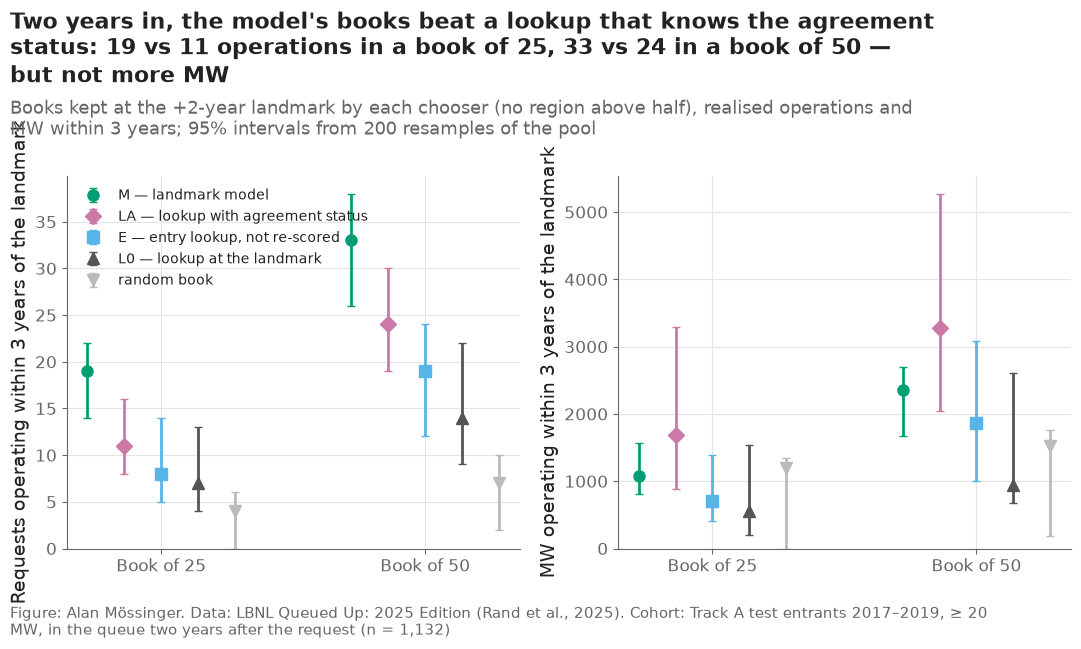

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
style = {"M": ("#009E73", "o"), "LA": ("#CC79A7", "D"), "E": ("#56B4E9", "s"), "L0": ("#555555", "^"), "random": ("#BBBBBB", "v")}
for ax, metric, unit in [(axes[0], "operations", "Requests operating within 3 years of the landmark"),
                         (axes[1], "MW", "MW operating within 3 years of the landmark")]:
    for c_i, c in enumerate(CHOOSERS):
        part = books[(books["chooser"] == c) & (books["metric"] == metric)].set_index("n").loc[NS]
        x = np.arange(len(NS)) + (c_i - 2) * 0.14
        color, marker = style[c]
        ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt=marker,
                    color=color, markersize=8, capsize=3, linewidth=2, label=LABELS[c])
    ax.set_xticks(range(len(NS)), [f"Book of {n}" for n in NS])
    ax.set_ylabel(unit)
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=10, loc="upper left")
m25, la25 = point["M|25|operations"], point["LA|25|operations"]
m50, la50 = point["M|50|operations"], point["LA|50|operations"]
c15_la = scored[(scored["id"] == "C15") & (scored["benchmark"] == "LA")]
verb = "beat" if c15_la["pass"].all() else "did not beat"
plots.finish(fig,
             f"Two years in, the model's books {verb} a lookup that knows the agreement status: "
             f"{m25} vs {la25} operations in a book of 25, {m50} vs {la50} in a book of 50 — but not more MW",
             f"Books kept at the +2-year landmark by each chooser (no region above half), realised operations and MW within 3 years; "
             f"95% intervals from {N_BOOT} resamples of the pool",
             f"Track A test entrants 2017–2019, ≥ 20 MW, in the queue two years after the request (n = {len(pool):,})")
plots.save_fig(fig, "F18_managed_book",
               "Operations and MW realised within three years by the books each chooser keeps two years after the request, with bootstrap intervals.",
               NOTEBOOK)
plt.show()

**Reading this.** Figure F18 shows the two results side by side. Left: the model's books (green) sit above every other chooser in requests that operated, with intervals that separate from the entry ranking and, narrowly, from the agreement-aware lookup. Right: in MW the lookup's books (pink) sit highest and widest — a handful of large plants decide MW totals, so MW rewards size as the registered backtest of notebook 16 did, and the model's ranking by probability does not chase size. For a developer counting projects that reach operation, or a lender counting financings that close, the left panel is the decision; for a grid planner counting megawatts, the right panel says the model adds nothing over the lookup. The random book shows the scale: 4 of 25.

## 6. What the books hold

Where the difference between the model's book and the agreement-aware lookup's comes from: how many requests in each book have a dated agreement known at the landmark, how the places split by region, how many requests the two books share, and the operations inside and outside the agreement-known group.

In [8]:
comp = []
for (c, n), chosen in point_masks.items():
    comp.append({"chooser": c, "n": n, "agreement_known": int((chosen & known).sum()),
                 "operated_with_agreement": int((chosen & known & built).sum()),
                 "operated_without_agreement": int((chosen & ~known & built).sum()),
                 **{f"places_{r}": int((chosen & (region == r)).sum()) for r in config.TRACK_A_REGIONS},
                 "shared_with_M": int((chosen & point_masks[("M", n)]).sum())})
composition = pd.DataFrame(comp)
composition.to_csv(paths.RESULTS / "managed_book_composition.csv", index=False)
composition

,chooser,n,agreement_known,operated_with_agreement,operated_without_agreement,places_ERCOT,places_PJM,places_CAISO,shared_with_M
0,M,25,13,13,6,12,12,1,25
1,M,50,25,23,10,25,24,1,50
2,LA,25,13,7,4,6,12,7,6
3,LA,50,25,14,10,18,25,7,28
4,E,25,4,2,6,12,12,1,6
5,E,50,8,6,13,25,25,0,25
6,L0,25,3,3,4,12,12,1,6
7,L0,50,4,3,11,24,25,1,24
8,random,25,4,2,2,10,12,3,0
9,random,50,8,4,3,19,25,6,2


**Reading this.** The difference is *within* the agreement group, not in finding it. Both 25-request books hold 13 requests with a known agreement (the cap stops either from holding more ERCOT); all 13 of the model's operated, 7 of the lookup's. The lookup ranks agreed requests by their region's curve alone and gave 7 places to CAISO; the model ranks them by technology, size, state and timing as well and kept 12 ERCOT, 12 PJM and 1 CAISO. The two books share only 6 of 25 requests (28 of 50). Outside the agreement group the model also does better (6 operations against 4 in 25). This is the evidence that the model's value at the milestone is not just the flag: given the same flag, it orders the requests better — but it does so in ERCOT, where the agreements are dated, and the PJM places in every book carry no agreement information at all.

## 7. The level at the landmark (C17)

Notebook 14 published the landmark model's calibration two years in: an intercept below zero, so the model predicts too much operation, as the drift of notebook 12 would lead one to expect. The registered repair uses only outcomes dated before the landmark: for entry cohort c, one intercept, slope fixed at 1, fitted on cohort c's operations within 1 year and cohort c − 1's within 2 years against the landmark model's entry view of the same requests. Both windows close by 31 December of c + 1, before the first landmark of cohort c. The repaired predictions are scored on the full +2 risk set and on its ≥ 20 MW part, with notebook 14's IPCW scoring and 200 resamples.

In [9]:
early = []
for c in range(config.TEST_YEARS[0] - 1, config.TEST_YEARS[1] + 1):
    part = track_a[track_a["q_year"] == c]
    part = part[landmark.risk_set(part, 0)]
    p = landmark.predict_at_landmark(fit_landmark, part, clean, 0, [1, 2], ia_dates, update_congestion=False, update_ia=True)
    op = (part["event"] == 1).to_numpy()
    early.append(pd.DataFrame({"q_year": c, "p1": p[1].to_numpy(), "p2": p[2].to_numpy(),
                               "y1": op & (part["duration_years"].to_numpy() <= 1), "y2": op & (part["duration_years"].to_numpy() <= 2)}))
early = pd.concat(early, ignore_index=True)
assert early["q_year"].max() + 1 < config.TEST_YEARS[1] + 2  # the newest window used closes before the newest landmark year

repair = []
for c in range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1):
    own, prev = early[early["q_year"] == c], early[early["q_year"] == c - 1]
    p_fit, y_fit = np.r_[own["p1"], prev["p2"]], np.r_[own["y1"], prev["y2"]].astype(float)
    repair.append({"entry_year": c, "intercept": drift.fit_intercept(p_fit, y_fit),
                   "own_1yr_requests": len(own), "own_1yr_operations": int(own["y1"].sum()), "own_1yr_predicted": own["p1"].sum(),
                   "prev_2yr_requests": len(prev), "prev_2yr_operations": int(prev["y2"].sum()), "prev_2yr_predicted": prev["p2"].sum(),
                   "information_closes": f"{c + 1}-12-31"})
repair = pd.DataFrame(repair)
repair.to_csv(paths.RESULTS / "landmark_level_repair.csv", index=False)
shift = risk["q_year"].map(repair.set_index("entry_year")["intercept"]).to_numpy()
p_raw = pred_m_risk[H].to_numpy(float)
p_rep = drift.apply_intercept(p_raw, shift)

cal_rows = []
for cohort, mask in [("all sizes", np.ones(len(risk), bool)), ("≥ 20 MW", risk["large"].to_numpy())]:
    sub_frame = risk[mask]
    d = sub_frame["duration_years"].to_numpy() - K
    e = sub_frame["event"].to_numpy()
    fu = ((pd.Timestamp(config.CENSOR_DATE) - sub_frame["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy() - K
    G = evaluation.censoring_km(fu, np.ones(len(sub_frame), bool))
    sub = {"M raw": p_raw[mask], "M repaired": p_rep[mask]}
    pt = evaluation.score_horizon(sub, d, e, H, G)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, H, G, sw), len(sub_frame), N_BOOT,
                                 SEED + 7 + (cohort == "≥ 20 MW"))
    t = evaluation.summarise(pt, draws, reference="M raw", level=LEVEL)
    t.insert(0, "cohort", cohort)
    t["observed"] = float(((e == 1) & (d <= H)).mean())
    t["mean_predicted"] = t["model"].map({"M raw": sub["M raw"].mean(), "M repaired": sub["M repaired"].mean()})
    cal_rows.append(t)
calibration = pd.concat(cal_rows, ignore_index=True)
calibration.to_csv(paths.RESULTS / "landmark_level_calibration.csv", index=False)
for i, line in scored.iterrows():
    if line["id"] == "C17":
        cohort = "all sizes" if "all sizes" in line["line"] else "≥ 20 MW"
        r = calibration[(calibration["cohort"] == cohort) & (calibration["model"] == "M repaired") & (calibration["metric"] == "intercept")].iloc[0]
        scored.loc[i, ["estimate", "low", "high"]] = [r["estimate"], r["low"], r["high"]]
        scored.loc[i, "pass"] = bool(r["low"] <= 0 <= r["high"])
display(repair.round(3))
calibration[calibration["metric"].isin(["intercept", "slope", "uno_c", "brier"])][
    ["cohort", "model", "metric", "estimate", "low", "high", "observed", "mean_predicted"]].round(3)

,entry_year,intercept,own_1yr_requests,own_1yr_operations,own_1yr_predicted,prev_2yr_requests,prev_2yr_operations,prev_2yr_predicted,information_closes
0,2017,0.135,434,8,6.974,507,25,22.520,2018-12-31
1,2018,-0.391,583,2,6.081,434,16,19.331,2019-12-31
2,2019,0.386,1047,30,14.291,583,14,17.042,2020-12-31


,cohort,model,metric,estimate,low,high,observed,mean_predicted
1,all sizes,M raw,brier,0.081,0.073,0.091,0.117,0.145
2,all sizes,M raw,slope,1.211,1.037,1.409,0.117,0.145
3,all sizes,M raw,intercept,-0.295,-0.442,-0.144,0.117,0.145
7,all sizes,M repaired,brier,0.085,0.078,0.094,0.117,0.160
8,all sizes,M repaired,slope,1.093,0.952,1.301,0.117,0.160
9,all sizes,M repaired,intercept,-0.438,-0.591,-0.285,0.117,0.160
12,all sizes,M raw,uno_c,0.797,0.758,0.831,0.117,0.145
14,all sizes,M repaired,uno_c,0.779,0.744,0.816,0.117,0.160
17,≥ 20 MW,M raw,brier,0.070,0.061,0.079,0.105,0.135
18,≥ 20 MW,M raw,slope,1.352,1.162,1.589,0.105,0.135


**Reading this.** The repair failed, and in the wrong direction. The raw landmark model predicts 14.5% operation within three years of the landmark against 11.7% observed (intercept −0.29 [−0.44, −0.14], as notebook 14 published). The early outcomes known at the landmark point the wrong way for the largest cohort: the 2019 entrants had 30 operations within their first year against 14.3 predicted — a burst of early completions — so their intercept moved *up* by +0.39, while their later operation rate was the lowest of the three; 2018's own first year (2 operations against 6.1) moved it down by −0.39, and 2017's moved it up by +0.14. After the repair the intercept is −0.44 [−0.59, −0.28] on all sizes and −0.50 [−0.68, −0.32] on ≥ 20 MW, and Uno's C falls from 0.797 to 0.779 because cohort-specific shifts reorder requests across cohorts. Both C17 lines fail. What it says for a lender: early completions are a poor guide to the level two years later; the level drift of notebook 12 is not visible early enough to repair at the landmark.

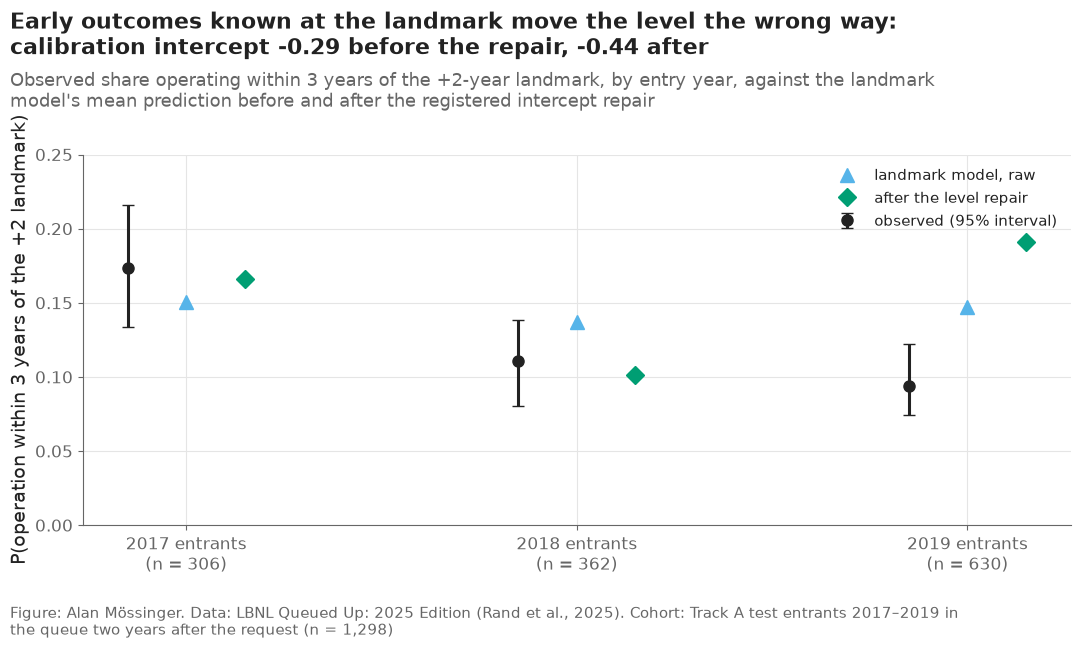

In [10]:
fig, ax = plt.subplots()
years = list(range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1))
risk_years = risk["q_year"].to_numpy()
d_all, e_all = risk["duration_years"].to_numpy() - K, risk["event"].to_numpy()
obs_all = (e_all == 1) & (d_all <= H)
boot_rng = np.random.default_rng(SEED + 11)
for i, y in enumerate(years):
    m = risk_years == y
    obs = obs_all[m]
    draws = [obs[boot_rng.integers(0, m.sum(), m.sum())].mean() for _ in range(N_BOOT)]
    ax.errorbar(i - 0.15, obs.mean(), yerr=[[obs.mean() - np.percentile(draws, lo_q)], [np.percentile(draws, hi_q) - obs.mean()]],
                fmt="o", color=plots.INK, capsize=4, markersize=8, label="observed (95% interval)" if i == 0 else None)
    ax.plot(i, p_raw[m].mean(), "^", color="#56B4E9", markersize=10, label="landmark model, raw" if i == 0 else None)
    ax.plot(i + 0.15, p_rep[m].mean(), "D", color="#009E73", markersize=9, label="after the level repair" if i == 0 else None)
ax.set_xticks(range(len(years)), [f"{y} entrants\n(n = {(risk_years == y).sum():,})" for y in years])
ax.set_ylabel("P(operation within 3 years of the +2 landmark)")
ax.set_ylim(0, max(0.25, ax.get_ylim()[1]))
ax.legend(fontsize=11)
r_all = calibration[(calibration["cohort"] == "all sizes") & (calibration["metric"] == "intercept")].set_index("model")
plots.finish(fig,
             f"Early outcomes known at the landmark move the level the wrong way: calibration intercept "
             f"{r_all.loc['M raw', 'estimate']:+.2f} before the repair, {r_all.loc['M repaired', 'estimate']:+.2f} after",
             "Observed share operating within 3 years of the +2-year landmark, by entry year, against the landmark model's mean "
             "prediction before and after the registered intercept repair",
             f"Track A test entrants 2017–2019 in the queue two years after the request (n = {len(risk):,})")
save(fig, "20_02_level_at_the_landmark",
     "Observed and predicted three-year operation after the two-year landmark by entry cohort, before and after the level repair.")
plt.show()

**Reading this.** Figure 20_02 makes the failure concrete: in 2017 the repair moves the prediction toward the observed share, in 2018 slightly past it, and in 2019 — the largest cohort, 630 of the 1,298 requests — it moves a prediction already too high (14.7% against 9.4% observed) further up, to 19.1%.

## 8. The registered verdict

The ten lines as registered, with the estimate and interval behind each, and the thesis rule applied as written in section 1.

In [11]:
scored["pass"] = scored["pass"].astype(bool)
scored.to_csv(paths.RESULTS / "success_criteria_v4_scored.csv", index=False)
thesis = bool(scored[(scored["id"] == "C15") & (scored["benchmark"] == "LA")]["pass"].all())
print(f"{int(scored['pass'].sum())} of {len(scored)} registered lines pass")
print("thesis rule:", "SUPPORTED — the model-managed book beats the agreement-aware lookup at +2 years" if thesis
      else "NOT SUPPORTED — the report keeps the current thesis (lookup at entry, model at the milestones against the entry view)")
scored[["id", "line", "estimate", "low", "high", "pass"]].round(3)

4 of 10 registered lines pass
thesis rule: SUPPORTED — the model-managed book beats the agreement-aware lookup at +2 years


,id,line,estimate,low,high,pass
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",8.000,1.000,11.000,True
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",9.000,0.975,13.000,True
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations r...",11.000,4.000,13.000,True
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations r...",14.000,7.000,19.000,True
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",-603.740,-2196.280,155.267,False
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",-913.810,-3090.407,179.603,False
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised ...",365.310,-337.203,846.370,False
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised ...",498.450,-871.152,1237.582,False
8,C17,"+2 landmark, all sizes: M after the level repa...",-0.438,-0.591,-0.285,False
9,C17,"+2 landmark, ≥ 20 MW: M after the level repair...",-0.495,-0.681,-0.319,False


**Reading this.** Four of ten registered lines pass: the four C15 operation lines. The four C16 MW lines and the two C17 level lines fail. The thesis rule written before scoring — both C15 lines against the agreement-aware lookup — is met, so the report can carry the stronger thesis **in the form registered**: at the two-year milestone, among utility-scale requests, a model-managed book of 25 or 50 holds more requests that reach operation than a careful analyst's lookup with the same dated agreement status. The qualifiers are part of the result: it does not hold in MW; the book-of-50 interval clears zero by less than one request; it rests on ERCOT's dated agreements, with none dated in the PJM part of the pool; and the model's level at the landmark is still too high and could not be repaired with what is known that day.

## 10. How much to add per region: the count book with a floor (F24; an extension of C15, not a registration)

C15 established that, two years in, the landmark model's book of 25 or 50 utility-scale requests holds more requests that reach operation than the agreement-aware lookup's. A company then asks how many to add in each region. This section answers with the registered pool, chooser and outcome, unchanged, and one rule: in each region, add requests in the model's order while the model's probability of operation within three years is at least the pool's own observed rate (`p_floor`, 119 of 1,132), then apply the registered cap of no region above half the book. The same curve is drawn for the lookup. It is scored on what happened, with the registered 200 resamples. Expected NPV per added request comes from notebook 15's NPV per MW at the operation date (section 8) and the landmark probabilities, discounted to the landmark. This is an extension of the registered result, written after it; it does not change C15–C17.

In [12]:
npv_tab = pd.read_csv(paths.RESULTS / "npv_table.csv")
NPV_BASE = npv_tab.set_index(["region", "tech", "cod_year"])["npv_per_mw_base"].to_dict()
LAST_COD, RATE = int(npv_tab["cod_year"].max()), 0.08
p_floor = float(built.mean())
pool_keys = pool["project_key"].astype(str).to_numpy()
pool_tech = pool["tech"].astype(str).to_numpy()
pool_year = pool["q_year"].to_numpy()
pool_mw = mw
P_M3 = SCORES["M"]
# expected NPV from the landmark: P(within 3 years) × NPV per MW at COD = entry + 2 + 2 (the middle year), discounted two years
exp_npv_each = np.array([P_M3[i] * NPV_BASE[(region[i], pool_tech[i], min(int(pool_year[i]) + 4, LAST_COD))] * pool_mw[i] / (1 + RATE) ** 2 for i in range(len(pool))])


def floor_book(score, region_arr, floor, cap_share, tiebreak):
    '''Add in the score's order while score ≥ floor, then the registered cap on any one region.'''
    n_floor = int((score >= floor).sum())
    if n_floor == 0:
        return np.zeros(len(score), bool)
    return portfolio.top_n_book(np.where(score >= floor, score, -np.inf), region_arr, n_floor, cap_share, tiebreak)


rng = np.random.default_rng(SEED + 10)
tie = rng.uniform(size=len(pool))
book_M = floor_book(SCORES["M"], region, p_floor, CAP, tie)
book_LA = floor_book(SCORES["LA"], region, p_floor, CAP, tie)
curve_rows, rec_rows = [], []
for name, score in [("M", SCORES["M"]), ("LA", SCORES["LA"])]:
    order = np.argsort(-score, kind="stable")
    for n in range(5, 451, 5):
        chosen = np.zeros(len(pool), bool)
        chosen[order[:n]] = True
        curve_rows.append({"chooser": name, "n": n, "operations": int((chosen & built).sum()), "mw": float(pool_mw[chosen & built].sum()),
                           "expected_operations": float(score[chosen].sum()), "min_p_in_book": float(score[order[n - 1]])})
curve = pd.DataFrame(curve_rows)
curve.to_csv(paths.RESULTS / "recommended_books_curve.csv", index=False)
boot_rows = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(pool), len(pool))
    tb = rng.uniform(size=len(pool))
    row = {}
    for name, score in [("M", SCORES["M"]), ("LA", SCORES["LA"])]:
        chosen = floor_book(score[idx], region[idx], p_floor, CAP, tb)
        for r in config.TRACK_A_REGIONS + ["all"]:
            m = chosen & ((region[idx] == r) if r != "all" else True)
            row[f"{name}|{r}|operations"] = int((m & built[idx]).sum())
            row[f"{name}|{r}|n"] = int(m.sum())
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)
for name, chosen in [("M", book_M), ("LA", book_LA)]:
    for r in config.TRACK_A_REGIONS + ["all"]:
        m = chosen & ((region == r) if r != "all" else True)
        ops = int((m & built).sum())
        d = boot[f"M|{r}|operations"] - boot[f"LA|{r}|operations"]
        rec_rows.append({"chooser": LABELS[name], "region": r, "requests_added": int(m.sum()), "expected_operations": float(SCORES[name][m].sum()),
                         "realised_operations": ops, "ops_low": float(np.percentile(boot[f"{name}|{r}|operations"], 2.5)),
                         "ops_high": float(np.percentile(boot[f"{name}|{r}|operations"], 97.5)), "realised_mw": float(pool_mw[m & built].sum()),
                         "expected_npv_$M": float(exp_npv_each[m].sum() / 1e6) if name == "M" else np.nan,
                         "pool_requests": int(((region == r) if r != "all" else np.ones(len(pool), bool)).sum()),
                         "pool_operations": int((built & ((region == r) if r != "all" else True)).sum()),
                         "diff_M_minus_LA_low": float(np.percentile(d, 2.5)), "diff_M_minus_LA_high": float(np.percentile(d, 97.5))})
recommended = pd.DataFrame(rec_rows)
recommended.to_csv(paths.RESULTS / "recommended_books.csv", index=False)
print(f"p_floor = {p_floor:.3f}; requests above the floor: model {int((SCORES['M'] >= p_floor).sum())}, lookup {int((SCORES['LA'] >= p_floor).sum())}; "
      f"after the {CAP:.0%} cap: model book {int(book_M.sum())}, lookup book {int(book_LA.sum())}")
recommended[["chooser", "region", "requests_added", "expected_operations", "realised_operations", "ops_low", "ops_high", "realised_mw", "expected_npv_$M", "pool_requests", "pool_operations", "diff_M_minus_LA_low", "diff_M_minus_LA_high"]].round(2)

p_floor = 0.105; requests above the floor: model 483, lookup 1006; after the 50% cap: model book 410, lookup book 860


,chooser,region,requests_added,expected_operations,realised_operations,ops_low,ops_high,realised_mw,expected_npv_$M,pool_requests,pool_operations,diff_M_minus_LA_low,diff_M_minus_LA_high
0,M — landmark model,ERCOT,167,60.61,70,55.00,87.02,11972.86,-3972.86,347,75,-9.02,-1.0
1,M — landmark model,PJM,241,42.34,24,15.00,34.00,1183.70,-139.33,665,37,-14.00,-2.0
2,M — landmark model,CAISO,2,0.88,1,0.00,3.00,38.00,-36.32,120,7,-6.00,0.0
3,M — landmark model,all,410,103.83,95,78.97,114.02,13194.56,-4148.51,1132,119,-24.00,-8.0
4,LA — lookup with agreement status,ERCOT,347,69.24,75,59.00,92.05,13394.52,NaN,347,75,-9.02,-1.0
5,LA — lookup with agreement status,PJM,503,96.10,34,22.00,43.00,1967.20,NaN,665,37,-14.00,-2.0
6,LA — lookup with agreement status,CAISO,10,4.02,4,0.98,8.00,1053.00,NaN,120,7,-6.00,0.0
7,LA — lookup with agreement status,all,860,169.36,113,92.00,130.00,16414.72,NaN,1132,119,-24.00,-8.0


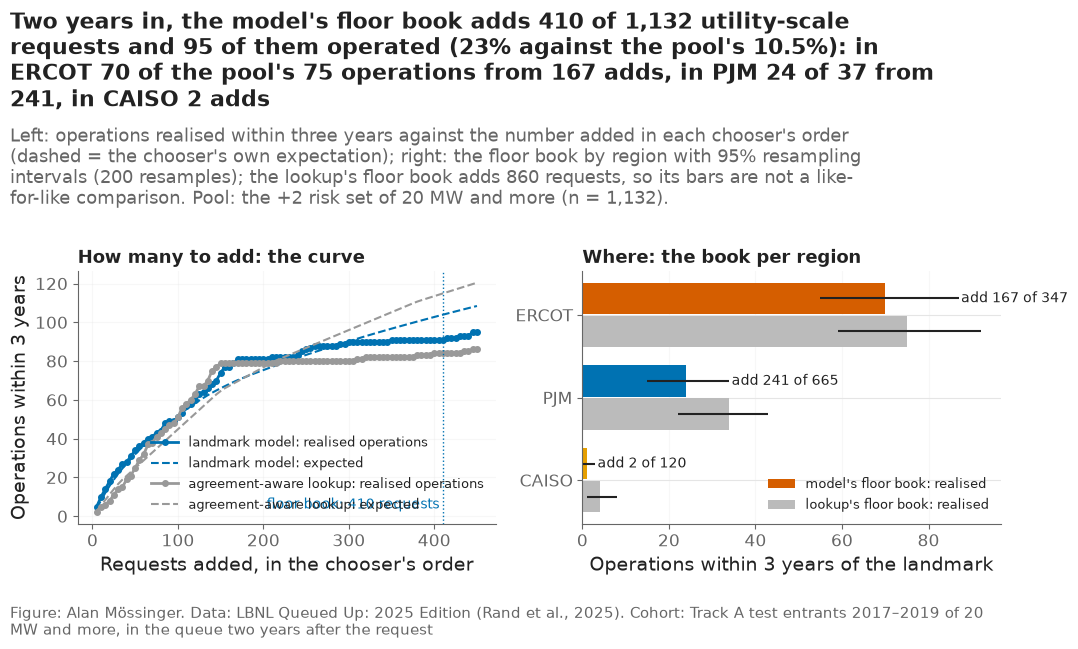

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
ax = axes[0]
for name, colour, label in [("M", "#0072B2", "landmark model"), ("LA", "#999999", "agreement-aware lookup")]:
    part = curve[curve["chooser"] == name]
    ax.plot(part["n"], part["operations"], "-o", color=colour, lw=2, ms=4, label=f"{label}: realised operations")
    ax.plot(part["n"], part["expected_operations"], "--", color=colour, lw=1.5, label=f"{label}: expected")
n_M = int(book_M.sum())
ax.axvline(n_M, color="#0072B2", lw=1, linestyle=":")
ax.text(n_M - 4, 112, f"floor book: {n_M} requests", fontsize=10, color="#0072B2", ha="right")
ax.set_xlabel("Requests added, in the chooser's order")
ax.set_ylabel("Operations within 3 years")
ax.set_title("How many to add: the curve", fontsize=13, loc="left")
ax.legend(fontsize=9.5, frameon=False, loc="lower right")
ax.grid(alpha=0.3)
ax = axes[1]
recM = recommended[(recommended["chooser"] == LABELS["M"]) & (recommended["region"] != "all")].set_index("region").loc[["ERCOT", "PJM", "CAISO"]]
recL = recommended[(recommended["chooser"] == LABELS["LA"]) & (recommended["region"] != "all")].set_index("region").reindex(["ERCOT", "PJM", "CAISO"])
y = np.arange(3)
ax.barh(y - 0.2, recM["realised_operations"], height=0.38, color=[plots.region_color(r) for r in recM.index], label="model's floor book: realised")
ax.hlines(y - 0.2, recM["ops_low"], recM["ops_high"], color=plots.INK, lw=1.5)
ax.barh(y + 0.2, recL["realised_operations"], height=0.38, color="#BBBBBB", label="lookup's floor book: realised")
ax.hlines(y + 0.2, recL["ops_low"], recL["ops_high"], color=plots.INK, lw=1.5)
for yy, (r, row) in zip(y, recM.iterrows()):
    ax.text(max(row["realised_operations"], row["ops_high"]) + 0.5, yy - 0.2, f"add {int(row['requests_added'])} of {int(row['pool_requests'])}", va="center", fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(recM.index)
ax.invert_yaxis()
ax.set_xlabel("Operations within 3 years of the landmark")
ax.set_title("Where: the book per region", fontsize=13, loc="left")
ax.legend(fontsize=9.5, frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
allM = recommended[(recommended["chooser"] == LABELS["M"]) & (recommended["region"] == "all")].iloc[0]
allL = recommended[(recommended["chooser"] == LABELS["LA"]) & (recommended["region"] == "all")].iloc[0]
pool_rate = {r: int(built[region == r].sum()) / int((region == r).sum()) for r in ["ERCOT", "PJM", "CAISO"]}
plots.finish(fig,
             f"Two years in, the model's floor book adds {n_M} of {len(pool):,} utility-scale requests and {int(allM['realised_operations'])} of them operated "
             f"({int(allM['realised_operations']) / n_M:.0%} against the pool's {p_floor:.1%}): in ERCOT {int(recM.loc['ERCOT', 'realised_operations'])} of the pool's "
             f"{int(recM.loc['ERCOT', 'pool_operations'])} operations from {int(recM.loc['ERCOT', 'requests_added'])} adds, in PJM "
             f"{int(recM.loc['PJM', 'realised_operations'])} of {int(recM.loc['PJM', 'pool_operations'])} from {int(recM.loc['PJM', 'requests_added'])}, in CAISO "
             f"{int(recM.loc['CAISO', 'requests_added'])} adds",
             f"Left: operations realised within three years against the number added in each chooser's order (dashed = the chooser's own expectation); "
             f"right: the floor book by region with 95% resampling intervals ({N_BOOT} resamples); the lookup's floor book adds {int(book_LA.sum())} requests, so its bars are not a like-for-like comparison. "
             f"Pool: the +2 risk set of 20 MW and more (n = {len(pool):,}).",
             "Track A test entrants 2017–2019 of 20 MW and more, in the queue two years after the request")
plots.save_fig(fig, "F24_book_per_region", "How many requests to add two years in and where: operations realised within three years of the landmark against the number added in the landmark model's and the agreement-aware lookup's order, and the model's floor book by region with resampling intervals.", NOTEBOOK)
plt.show()

**Reading this.** Two answers, one for how much and one for where, and a warning about value.

- **How much.** The model's order holds its edge for about the first hundred adds: its first 25 picks held 22 operations against 11 for the lookup, its first 50 held 34 against 25, at 100 both held 51, and beyond 150 the lookup has nothing left to add while the model still finds a few. The probability floor (the pool's own 10.5%) lets 410 requests through after the region cap; 95 of them operated, 23% against the pool's 10.5%, and the model's own expectation for that book was 104, so it was close to calibrated on the count. The lookup's floor passes 860 requests, three quarters of the pool, with 113 operations (13%): a floor on the lookup is barely a screen.
- **Where.** ERCOT is where the two-year review pays: 167 adds out of 347 captured 70 of the region's 75 operations (42% hit rate, double the pool's 22%). In PJM the model adds 241 of 665 for 24 of the region's 37 operations (10% against 6%): without dated agreements it separates little, and a company should add fewer there and review again later. In CAISO the floor admits 2 requests; one operated.
- **The warning.** Counted in expected NPV at merchant prices (notebook 15), the ERCOT adds are worth −$4.0 billion in total, because most are solar and storage whose plants do not earn their capital back without a contract. The count book answers "which requests will exist"; the value layer and the gates of notebook 16 answer "which are worth owning". A company with contracted offtake in ERCOT should add by this book; one selling at merchant prices should add only the wind in it.

## 11. Checks

In [14]:
pl = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
nb14 = pl[(pl["landmark"] == "2") & (pl["horizon_after"] == H)].set_index("project_key")["agreement updated"]
reproduced = float(np.abs(nb14.reindex(pool["project_key"].astype(str)).to_numpy() - SCORES["M"]).max())
checks = pd.DataFrame([
    {"check": "registration file unchanged since it was committed (decision #58)",
     "value": REGISTERED_SHA[:16], "pass": hashlib.sha256(reg_path.read_bytes()).hexdigest() == REGISTERED_SHA},
    {"check": "the refit reproduces notebook 14's landmark predictions on the pool", "value": reproduced, "pass": reproduced < 1e-6},
    {"check": "every request of the pool followed 3 years after the landmark", "value": round(float(follow_up.min()), 3),
     "pass": bool((follow_up >= H - 0.01).all())},
    {"check": "no book exceeds the region cap", "value": max(int(composition[[f"places_{r}" for r in config.TRACK_A_REGIONS]].max(axis=1).max()), 0),
     "pass": bool((composition[[f"places_{r}" for r in config.TRACK_A_REGIONS]].max(axis=1) <= np.floor(CAP * composition["n"])).all())},
    {"check": "level repair uses only outcomes closed before the cohort's first landmark",
     "value": "windows close 31 Dec of c + 1", "pass": bool((repair["information_closes"].str[:4].astype(int) < repair["entry_year"] + 2).all())},
    {"check": "every registered line scored with an interval", "value": int(scored[["low", "high"]].isna().any(axis=1).sum()),
     "pass": not scored[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F18 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F18_managed_book.png").exists() and (paths.FIGURES / "F18_managed_book.svg").exists()},
])
checks.to_csv(paths.RESULTS / "managed_book_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.1 min


,check,value,pass
0,registration file unchanged since it was commi...,0ea97d5aac9f208c,True
1,the refit reproduces notebook 14's landmark pr...,0.0,True
2,every request of the pool followed 3 years aft...,3.016,True
3,no book exceeds the region cap,25,True
4,level repair uses only outcomes closed before ...,windows close 31 Dec of c + 1,True
5,every registered line scored with an interval,0,True
6,F18 saved as PNG and SVG,2,True


## Takeaways

- PJM's queue export and ERCOT's GIS report, now on disk, add no dated and outcome-blind landmark (notebook 13, decision #57); the test therefore runs on the agreement dates of the two LBNL editions, which reach ERCOT and CAISO and almost never PJM.
- Registered before scoring (decision #58), the milestone-managed book passes on operations: two years in, the model's book of 25 holds 19 requests that operated against 11 for a lookup that knows the agreement status (+8 [+1, +11]), and 33 against 24 in a book of 50 (+9 [+0.98, +13]); against the unchanged entry ranking +11 and +14.
- It fails on MW: the lookup's books realise more megawatts (−604 and −914 MW, intervals including zero), because MW totals follow a few large plants and the model does not chase size.
- The gain comes from ordering requests *within* the agreement group (13 of 13 against 7 of 13 operated): the model's value at the milestone is more than the flag, but it is shown where agreements are dated.
- The level repair at the landmark fails and moves the intercept the wrong way (−0.29 to −0.44): early completions do not foretell the level two years on.
- **What goes to the report:** F18; the ten registered lines (4 of 10 pass); the thesis stated in its registered form with its four qualifiers; figure 20_02 in the appendix; the PJM gap as the main limitation.
- **How much to add, and where (section 10, F24; an extension of C15):** the model's order keeps its edge over the agreement-aware lookup for about the first hundred adds (22 vs 11 operations at 25, 34 vs 25 at 50, 51 each at 100). A floor at the pool's own rate admits 410 requests, 95 of which operated (23%); ERCOT is where the review pays (167 adds capture 70 of 75 operations), PJM separates little (241 adds for 24 of 37), CAISO admits 2. At merchant prices the ERCOT adds have a negative expected NPV: the count book says which requests will exist, the gates of notebook 16 say which are worth owning.